## Homework 12

In this homework, you are going to use the code from ```TrafficSignsClassification``` notebook and create your own traffic sign classifier.

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'    # треба задати до import keras

import pickle
import numpy as np
from sklearn.utils import shuffle
from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 6]

### Step 1
Use the data from ```data/subset_homework.pckl``` (or the ```data/subset_homework``` folder) and visualize some examples. How many images are there for each class?

У класі 0 є 2220 картинок, у класі 1 є 2250. Класи майже порівну.

In [2]:
# Дані GTSRB з курсу (28x28, відтінки сірого)
path = '/Users/andriizemlianyi/Code/zemand-learning/Computer Vision/r_d/r_d-computer-vision-v2-master/lesson_12/data/subset_homework.pckl'
with open(path, 'rb') as f:
    data = pickle.load(f)

images_0 = data['class_id_0']    # знаки першого класу
images_1 = data['class_id_1']    # знаки другого класу
labels_0 = [0] * len(images_0)   # мітка 0 для кожної картинки класу 0
labels_1 = [1] * len(images_1)   # мітка 1 для кожної картинки класу 1

In [3]:
# Скільки картинок у кожному класі
print('Клас 0:', len(images_0))
print('Клас 1:', len(images_1))

Клас 0: 2220
Клас 1: 2250


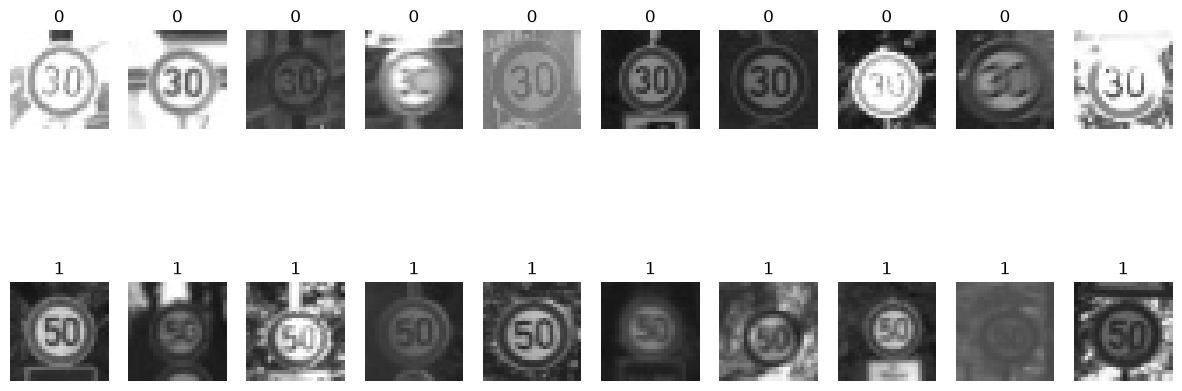

In [4]:
# Перший рядок: клас 0, другий рядок: клас 1
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(images_0[i], cmap='gray', vmin=0, vmax=255)
    plt.title(0), plt.axis(False)

for i in range(10):
    plt.subplot(2, 10, 10 + i + 1)
    plt.imshow(images_1[i], cmap='gray', vmin=0, vmax=255)
    plt.title(1), plt.axis(False)

In [5]:
# Об'єднуємо обидва класи і перемішуємо картинки разом з мітками
images = images_0 + images_1
labels = labels_0 + labels_1
images, labels = shuffle(images, labels)
images = np.array(images)
labels = np.array(labels)

# Розгортаємо кожну картинку 28x28 у рядок з 784 чисел
pixels = []
for image in images:
    pixels.append(image.flatten())

# Масштабуємо значення з 0-255 до 0-1
pixels = np.array(pixels) / 255
print(pixels.shape)

(4470, 784)


### Step 2
Run the training with one single neuron (as we did in the lecture). What accuracy can you achieve?

Один нейрон дає точність приблизно 0.90. Якщо тренувати довше (50 epochs), виходить близько 0.95.

In [6]:
import keras
from keras import Model
from keras.layers import Dense, Input

inputs = Input(shape=(784,))                       # 784 пікселі на вході
outputs = Dense(1, activation="linear")(inputs)    # один нейрон
model = Model(inputs, outputs)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           785 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 785 (3.07 KB)

 Trainable params: 785 (3.07 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(optimizer='adam', loss='mean_squared_error')
history = model.fit(pixels, labels, epochs=10, batch_size=32, verbose=2)

Epoch 1/10
140/140 - 0s - 3ms/step - loss: 0.2972
Epoch 2/10
140/140 - 0s - 3ms/step - loss: 0.2156
Epoch 3/10
140/140 - 0s - 2ms/step - loss: 0.1763
Epoch 4/10
140/140 - 0s - 2ms/step - loss: 0.1516
Epoch 5/10
140/140 - 0s - 3ms/step - loss: 0.1352
Epoch 6/10
140/140 - 0s - 3ms/step - loss: 0.1247
Epoch 7/10
140/140 - 0s - 3ms/step - loss: 0.1117
Epoch 8/10
140/140 - 0s - 3ms/step - loss: 0.1067
Epoch 9/10
140/140 - 0s - 2ms/step - loss: 0.1053
Epoch 10/10
140/140 - 0s - 3ms/step - loss: 0.0971


In [8]:
predictions = model.predict(pixels, verbose=0).squeeze()
predictions = (predictions > 0.5).astype(int)    # поріг 0.5 перетворює число на клас

correct = 0
for prediction, label in zip(predictions, labels):
    if prediction == label:
        correct = correct + 1

print('Accuracy', correct / len(labels))

Accuracy 0.9214765100671141


### Step 3
Make further modifications to improve the accuracy (e.g. add more neurons, more layers, etc.). What is the maximum accuracy you can achieve?

*Note: the accuracy you compute here is measured on the same images the model was trained on. We will discuss how to evaluate a model properly in one of the next lessons.*

При використанні двох hidden-шарів (ReLU) і одним вихідним нейроном точність близько 0.98. Нелінійність (ReLU) і більше нейронів дають очевидно кращий результат, ніж один нейрон.

In [9]:
inputs = Input(shape=(784,))
x = Dense(32, activation="relu")(inputs)         # перший hidden-шар
x = Dense(16, activation="relu")(x)              # другий hidden-шар
outputs = Dense(1, activation="linear")(x)       # один вихідний нейрон
model = Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,665 (100.25 KB)

 Trainable params: 25,665 (100.25 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(optimizer='adam', loss='mean_squared_error')
history = model.fit(pixels, labels, epochs=50, batch_size=32, verbose=2)

Epoch 1/50
140/140 - 0s - 3ms/step - loss: 0.2634
Epoch 2/50
140/140 - 0s - 3ms/step - loss: 0.1808
Epoch 3/50
140/140 - 0s - 3ms/step - loss: 0.1234
Epoch 4/50
140/140 - 0s - 3ms/step - loss: 0.1025
Epoch 5/50
140/140 - 0s - 3ms/step - loss: 0.0915
Epoch 6/50
140/140 - 0s - 3ms/step - loss: 0.0794
Epoch 7/50
140/140 - 0s - 3ms/step - loss: 0.0781
Epoch 8/50
140/140 - 0s - 3ms/step - loss: 0.0725
Epoch 9/50
140/140 - 0s - 3ms/step - loss: 0.0666
Epoch 10/50
140/140 - 0s - 3ms/step - loss: 0.0617
Epoch 11/50
140/140 - 0s - 3ms/step - loss: 0.0562
Epoch 12/50
140/140 - 0s - 3ms/step - loss: 0.0528
Epoch 13/50
140/140 - 0s - 3ms/step - loss: 0.0508
Epoch 14/50
140/140 - 0s - 3ms/step - loss: 0.0480
Epoch 15/50
140/140 - 0s - 3ms/step - loss: 0.0480
Epoch 16/50
140/140 - 0s - 3ms/step - loss: 0.0419
Epoch 17/50
140/140 - 0s - 3ms/step - loss: 0.0581
Epoch 18/50
140/140 - 0s - 3ms/step - loss: 0.0450
Epoch 19/50
140/140 - 0s - 3ms/step - loss: 0.0555
Epoch 20/50
140/140 - 0s - 3ms/step - lo

In [11]:
predictions = model.predict(pixels, verbose=0).squeeze()
predictions = (predictions > 0.5).astype(int)

correct = 0
for prediction, label in zip(predictions, labels):
    if prediction == label:
        correct = correct + 1

print('Accuracy', correct / len(labels))

Accuracy 0.9821029082774049


### Bonus question
Stack two ```Dense``` layers with ```activation="linear"``` on top of each other. Do you get a better model than with one single neuron? Why (not)? Hint: have a look at the slide about the neural network and non-linearity.

Модель не стає кращою за один нейрон. Бо без нелінійної активації скільки глибини ти не додасиш, це не буде мати жодного сенсу.

In [12]:
inputs = Input(shape=(784,))
x = Dense(16, activation="linear")(inputs)
outputs = Dense(1, activation="linear")(x)
model = Model(inputs, outputs)
model.compile(optimizer='adam', loss='mean_squared_error')
history = model.fit(pixels, labels, epochs=10, batch_size=32, verbose=2)

Epoch 1/10
140/140 - 0s - 3ms/step - loss: 0.3780
Epoch 2/10
140/140 - 0s - 3ms/step - loss: 0.1780
Epoch 3/10
140/140 - 0s - 3ms/step - loss: 0.1584
Epoch 4/10
140/140 - 0s - 3ms/step - loss: 0.1308
Epoch 5/10
140/140 - 0s - 3ms/step - loss: 0.1137
Epoch 6/10
140/140 - 0s - 3ms/step - loss: 0.1023
Epoch 7/10
140/140 - 0s - 3ms/step - loss: 0.1007
Epoch 8/10
140/140 - 0s - 3ms/step - loss: 0.0960
Epoch 9/10
140/140 - 0s - 3ms/step - loss: 0.1059
Epoch 10/10
140/140 - 0s - 3ms/step - loss: 0.0858


In [13]:
predictions = model.predict(pixels, verbose=0).squeeze()
predictions = (predictions > 0.5).astype(int)

correct = 0
for prediction, label in zip(predictions, labels):
    if prediction == label:
        correct = correct + 1

print('Accuracy', correct / len(labels))

Accuracy 0.962192393736018
